<a href="https://colab.research.google.com/github/kangtayie/Machine-Learning_class/blob/main/FashionMNIST_classification_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. 라이브러리 임포트 및 데이터 로드

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers

from sklearn.metrics import confusion_matrix, classification_report

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# 라벨 번호(0~9)에 대응하는 의류 이름 (책 341쪽 표)
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


X_train shape: (60000, 28, 28)
X_test shape: (10000, 28, 28)
클래스별 개수: [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


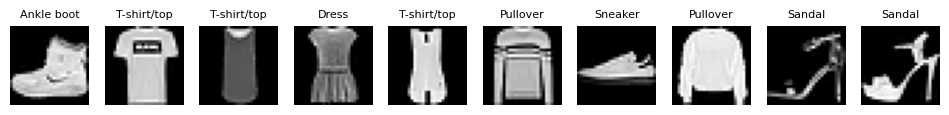

In [2]:
# 2. 데이터 확인

# 데이터 형태와 클래스별 개수 확인
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("클래스별 개수:", np.bincount(y_train))

plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]], fontsize=8)
    plt.axis("off")
plt.show()

In [3]:
# 3. 전처리

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# 정규화
X_train = X_train / 255.0
X_test = X_test / 255.0

# 정답 라벨을 원-핫 인코딩
y_train_oh = tf.keras.utils.to_categorical(y_train, num_classes=10)
y_test_oh = tf.keras.utils.to_categorical(y_test, num_classes=10)

print("X_train:", X_train.shape, "X_test:", X_test.shape)

X_train: (60000, 28, 28, 1) X_test: (10000, 28, 28, 1)


In [4]:
# 4. CNN 모델 구조

model = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # [합성곱층 1] 3x3 필터 32개로 윤곽선·모서리 같은 기본 특징 추출
    layers.Conv2D(32, (3, 3), activation="relu"),
    # [풀링층 1] 2x2 영역에서 최댓값만 남겨 크기를 절반으로 축소
    layers.MaxPooling2D((2, 2)),

    # [합성곱층 2] 필터 64개로 소매·밑창·손잡이 같은 더 복잡한 형태 추출
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # [Flatten] 2차원 특징맵을 1줄로 펼쳐 Dense층에 전달
    layers.Flatten(),

    # [분류부] 책의 Dense 모델처럼 완전연결층으로 최종 분류
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

In [5]:
# 5. 컴파일

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",   # 원-핫 라벨용 다중분류 손실함수
    metrics=["accuracy"]
)

In [6]:
# 6. 모델 구조 출력

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# 7. 학습

history = model.fit(
    X_train, y_train_oh,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.7893 - loss: 0.5776 - val_accuracy: 0.8624 - val_loss: 0.3765
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 14s 5ms/step - accuracy: 0.8650 - loss: 0.3724 - val_accuracy: 0.8810 - val_loss: 0.3196
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8818 - loss: 0.3229 - val_accuracy: 0.8864 - val_loss: 0.3036
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8920 - loss: 0.2906 - val_accuracy: 0.8988 - val_loss: 0.2750
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9029 - loss: 0.2641 - val_accuracy: 0.9014 - val_loss: 0.2705
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9097 - loss: 0.2454 - val_accuracy: 0.9080 - val_loss: 0.2524
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9154 - loss: 0.2279 - val_accuracy: 0.9086 - val_loss: 0.2480
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9208 - loss: 0.2115 - val_accuracy: 

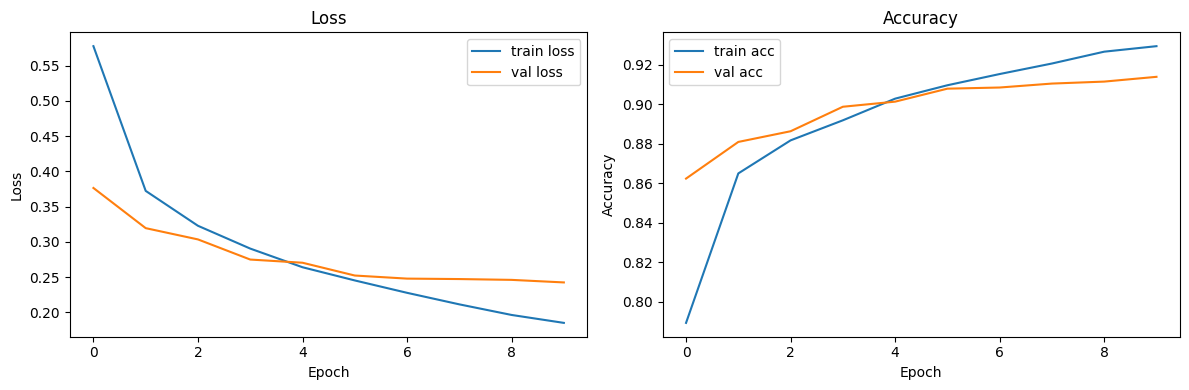

In [8]:
# 8. 학습 곡선 시각화

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="train acc")
plt.plot(history.history["val_accuracy"], label="val acc")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

Test loss: 0.2524
Test accuracy: 0.9103
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
              precision    recall  f1-score   support

 T-shirt/top       0.85      0.86      0.86      1000
     Trouser       1.00      0.97      0.99      1000
    Pullover       0.86      0.88      0.87      1000
       Dress       0.89      0.93      0.91      1000
        Coat       0.84      0.89      0.86      1000
      Sandal       0.99      0.98      0.98      1000
       Shirt       0.76      0.68      0.72      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.97      0.96      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



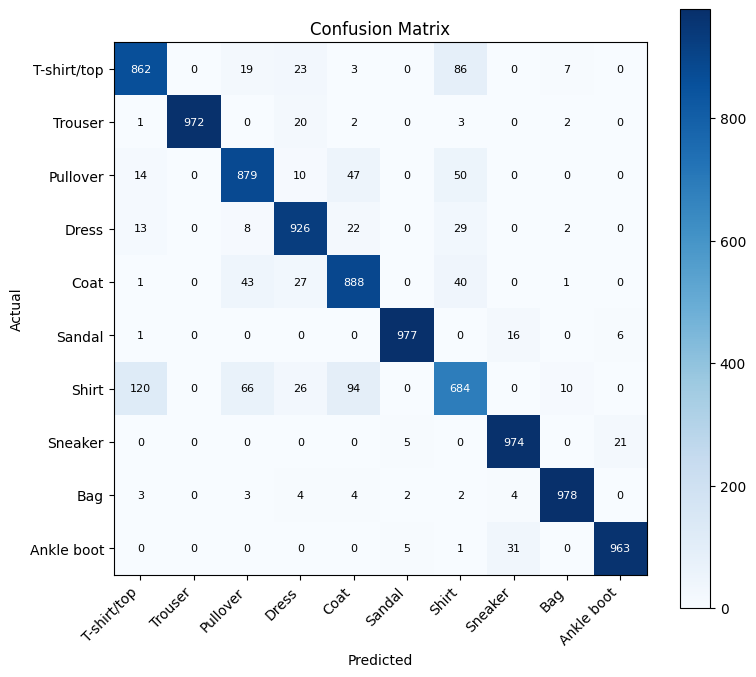

In [9]:
# 9. 테스트셋 평가

# 한 번도 보지 않은 테스트 데이터로 최종 성능 평가
test_loss, test_acc = model.evaluate(X_test, y_test_oh, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

y_pred = np.argmax(model.predict(X_test), axis=1)

# 범주별 정밀도/재현율/F1
print(classification_report(y_test, y_pred, target_names=class_names))

# 혼동행렬
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
plt.xticks(range(10), class_names, rotation=45, ha="right")
plt.yticks(range(10), class_names)
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.show()

틀린 개수: 897 / 10000


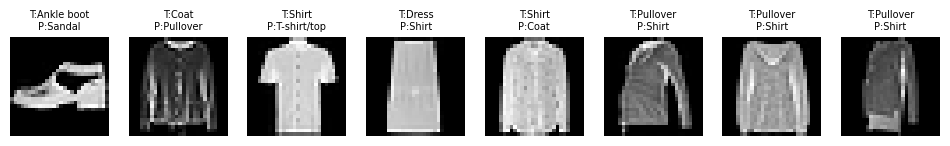

In [10]:
# 10. 틀린 예측 확인

# 모델이 틀린 이미지만 골라서 보기
wrong = np.where(y_pred != y_test)[0]
print(f"틀린 개수: {len(wrong)} / {len(y_test)}")

plt.figure(figsize=(12, 3))
for k, idx in enumerate(wrong[:8]):   # 최대 8개만 표시
    plt.subplot(1, 8, k + 1)
    plt.imshow(X_test[idx].reshape(28, 28), cmap="gray")
    # T=정답, P=예측
    plt.title(f"T:{class_names[y_test[idx]]}\nP:{class_names[y_pred[idx]]}", fontsize=7)
    plt.axis("off")
plt.show()